# LAB 1 - Bài 2 (Trang 28): Phân tích và tiền xử lý dữ liệu Bank Marketing

### 1. Khai báo thư viện và đọc dữ liệu

In [ ]:
HO_TEN = "Nguyễn Đoàn Ngọc Hiệp"
MSSV = "6451071023"

def info():
    print(f"Họ và tên: {HO_TEN} - MSSV: {MSSV}")
    print("-" * 30)

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

# Đọc tập dữ liệu Bank Marketing (các cột phân tách bằng dấu ;)
df = pd.read_csv('bank.csv', sep=';')

info()
display(df.head())

Họ và tên: Nguyễn Đoàn Ngọc Hiệp - MSSV: 6451071023
------------------------------


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


### 2. Khảo sát sơ bộ dữ liệu

In [ ]:
info()
print("--- Kích thước dữ liệu (dòng, cột) ---")
print(df.shape)

print("\n--- Thông tin cấu trúc dữ liệu ---")
df.info()

print("\n--- Số lượng giá trị thiếu (Null) ---")
print(df.isnull().sum())

print("\n--- Số dòng trùng lặp ---")
print(df.duplicated().sum())

Họ và tên: Nguyễn Đoàn Ngọc Hiệp - MSSV: 6451071023
------------------------------
--- Kích thước dữ liệu (dòng, cột) ---
(4521, 17)

--- Thông tin cấu trúc dữ liệu ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        4521 non-null   int64 
 1   job        4521 non-null   object
 2   marital    4521 non-null   object
 3   education  4521 non-null   object
 4   default    4521 non-null   object
 5   balance    4521 non-null   int64 
 6   housing    4521 non-null   object
 7   loan       4521 non-null   object
 8   contact    4521 non-null   object
 9   day        4521 non-null   int64 
 10  month      4521 non-null   object
 11  duration   4521 non-null   int64 
 12  campaign   4521 non-null   int64 
 13  pdays      4521 non-null   int64 
 14  previous   4521 non-null   int64 
 15  poutcome   4521 non-null   object
 16  y          4521 n

Dữ liệu không có ô rỗng (Null), nhưng một số cột phân loại dùng chuỗi `unknown` để biểu diễn giá trị chưa biết. Kiểm tra số lượng:

In [ ]:
info()
cat_cols = df.select_dtypes(include='object').columns
for col in cat_cols:
    n = (df[col] == 'unknown').sum()
    if n > 0:
        print(f"{col:10s}: {n:5d} giá trị 'unknown' ({n / len(df) * 100:.1f}%)")

Họ và tên: Nguyễn Đoàn Ngọc Hiệp - MSSV: 6451071023
------------------------------
job       :    38 giá trị 'unknown' (0.8%)
education :   187 giá trị 'unknown' (4.1%)
contact   :  1324 giá trị 'unknown' (29.3%)
poutcome  :  3705 giá trị 'unknown' (82.0%)


### 3. Thống kê mô tả các thuộc tính

In [ ]:
info()
# Biến định lượng
display(df.describe())

# Biến phân loại
display(df.describe(include=['O']))

Họ và tên: Nguyễn Đoàn Ngọc Hiệp - MSSV: 6451071023
------------------------------


,age,balance,day,duration,campaign,pdays,previous
count,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000
mean,41.170095,1422.657819,15.915284,263.961292,2.793630,39.766645,0.542579
std,10.576211,3009.638142,8.247667,259.856633,3.109807,100.121124,1.693562
min,19.000000,-3313.000000,1.000000,4.000000,1.000000,-1.000000,0.000000
25%,33.000000,69.000000,9.000000,104.000000,1.000000,-1.000000,0.000000
50%,39.000000,444.000000,16.000000,185.000000,2.000000,-1.000000,0.000000
75%,49.000000,1480.000000,21.000000,329.000000,3.000000,-1.000000,0.000000
max,87.000000,71188.000000,31.000000,3025.000000,50.000000,871.000000,25.000000


,job,marital,education,default,housing,loan,contact,month,poutcome,y
count,4521,4521,4521,4521,4521,4521,4521,4521,4521,4521
unique,12,3,4,2,2,2,3,12,4,2
top,management,married,secondary,no,yes,no,cellular,may,unknown,no
freq,969,2797,2306,4445,2559,3830,2896,1398,3705,4000


Họ và tên: Nguyễn Đoàn Ngọc Hiệp - MSSV: 6451071023
------------------------------
y
no     4000
yes     521
Name: count, dtype: int64
y
no     0.885
yes    0.115
Name: proportion, dtype: float64


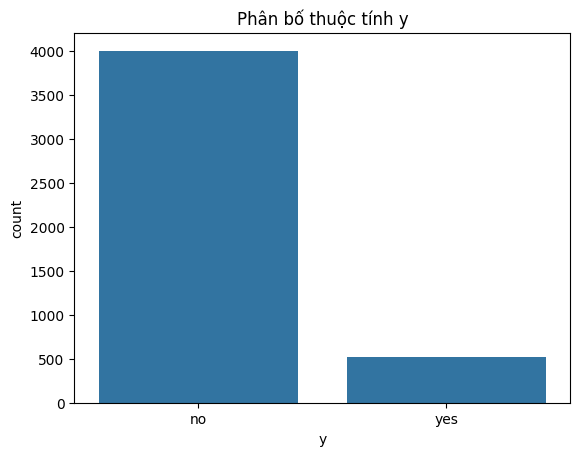

In [ ]:
info()
# Phân bố thuộc tính quyết định y (khách hàng có đăng ký tiền gửi kỳ hạn hay không)
print(df['y'].value_counts())
print(df['y'].value_counts(normalize=True).round(3))

sns.countplot(x='y', data=df)
plt.title('Phân bố thuộc tính y')
plt.show()

### 4. Tiền xử lý dữ liệu
#### 4.1 Xử lý giá trị `unknown`
- `job`, `education`: ít `unknown` → đổi thành NaN rồi điền bằng giá trị xuất hiện nhiều nhất (mode).
- `contact`, `poutcome`: `unknown` chiếm tỷ lệ lớn → giữ nguyên như một loại riêng.

In [ ]:
info()
for col in ['job', 'education']:
    df[col] = df[col].replace('unknown', np.nan)
    print(f"{col}: thiếu {df[col].isnull().sum()} giá trị, điền bằng '{df[col].mode()[0]}'")
    df[col] = df[col].fillna(df[col].mode()[0])

print("-" * 30)
print("Số lượng giá trị thiếu sau khi điền:")
print(df.isnull().sum())

Họ và tên: Nguyễn Đoàn Ngọc Hiệp - MSSV: 6451071023
------------------------------
job: thiếu 38 giá trị, điền bằng 'management'
education: thiếu 187 giá trị, điền bằng 'secondary'
------------------------------
Số lượng giá trị thiếu sau khi điền:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64


#### 4.2 Xóa dòng trùng lặp (nếu có)

In [ ]:
info()
print("Số dòng trước:", len(df))
df = df.drop_duplicates()
print("Số dòng sau  :", len(df))

Họ và tên: Nguyễn Đoàn Ngọc Hiệp - MSSV: 6451071023
------------------------------
Số dòng trước: 4521
Số dòng sau  : 4521


### 5. Mã hóa dữ liệu phân loại
#### 5.1 Mã hóa thuộc tính quyết định y và các cột yes/no

In [ ]:
info()
yes_no = {'yes': 1, 'no': 0}
df['Subscribe_encoded'] = df['y'].map(yes_no)
for col in ['default', 'housing', 'loan']:
    df[col] = df[col].map(yes_no)

print(df[['y', 'Subscribe_encoded', 'default', 'housing', 'loan']].head())

Họ và tên: Nguyễn Đoàn Ngọc Hiệp - MSSV: 6451071023
------------------------------
    y  Subscribe_encoded  default  housing  loan
0  no                  0        0        0     0
1  no                  0        0        1     1
2  no                  0        0        1     0
3  no                  0        0        1     1
4  no                  0        0        1     0


#### 5.2 Mã hóa thuộc tính có thứ tự: `education`, `month`

In [ ]:
info()
df['education'] = df['education'].map({'primary': 1, 'secondary': 2, 'tertiary': 3})

months = {'jan': 1, 'feb': 2, 'mar': 3, 'apr': 4, 'may': 5, 'jun': 6,
          'jul': 7, 'aug': 8, 'sep': 9, 'oct': 10, 'nov': 11, 'dec': 12}
df['month'] = df['month'].map(months)

print(df[['education', 'month']].head())

Họ và tên: Nguyễn Đoàn Ngọc Hiệp - MSSV: 6451071023
------------------------------
   education  month
0          1     10
1          2      5
2          3      4
3          3      6
4          2      5


#### 5.3 Mã hóa One-hot cho các thuộc tính không có thứ tự: `job`, `marital`, `contact`, `poutcome`

In [ ]:
info()
df = pd.get_dummies(df, columns=['job', 'marital', 'contact', 'poutcome'], dtype=int)
print("Số cột sau khi One-hot:", df.shape[1])
df.head()

Họ và tên: Nguyễn Đoàn Ngọc Hiệp - MSSV: 6451071023
------------------------------
Số cột sau khi One-hot: 35


,age,education,default,balance,housing,loan,day,month,duration,campaign,...,marital_divorced,marital_married,marital_single,contact_cellular,contact_telephone,contact_unknown,poutcome_failure,poutcome_other,poutcome_success,poutcome_unknown
0,30,1,0,1787,0,0,19,10,79,1,...,0,1,0,1,0,0,0,0,0,1
1,33,2,0,4789,1,1,11,5,220,1,...,0,1,0,1,0,0,1,0,0,0
2,35,3,0,1350,1,0,16,4,185,1,...,0,0,1,1,0,0,1,0,0,0
3,30,3,0,1476,1,1,3,6,199,4,...,0,1,0,0,0,1,0,0,0,1
4,59,2,0,0,1,0,5,5,226,1,...,0,1,0,0,0,1,0,0,0,1


### 6. Chuẩn hóa dữ liệu (Min-max normalization)
Công thức: `new_value = (value - min) / (max - min)`, đưa giá trị về khoảng 0 – 1.

In [ ]:
info()
num_cols = ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

df_norm = df.copy()
for col in num_cols:
    df_norm[col] = (df[col] - df[col].min()) / (df[col].max() - df[col].min())

display(df_norm[num_cols].describe().loc[['min', 'max']])
df_norm[num_cols].head()

Họ và tên: Nguyễn Đoàn Ngọc Hiệp - MSSV: 6451071023
------------------------------


,age,balance,day,duration,campaign,pdays,previous
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0,1.0,1.0


,age,balance,day,duration,campaign,pdays,previous
0,0.161765,0.068455,0.600000,0.024826,0.000000,0.000000,0.00
1,0.205882,0.108750,0.333333,0.071500,0.000000,0.389908,0.16
2,0.235294,0.062590,0.500000,0.059914,0.000000,0.379587,0.04
3,0.161765,0.064281,0.066667,0.064548,0.061224,0.000000,0.00
4,0.588235,0.044469,0.133333,0.073486,0.000000,0.000000,0.00


### 7. Kết quả sau tiền xử lý

In [ ]:
info()
df_norm.info()
df_norm.head(10)

Họ và tên: Nguyễn Đoàn Ngọc Hiệp - MSSV: 6451071023
------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 35 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                4521 non-null   float64
 1   education          4521 non-null   int64  
 2   default            4521 non-null   int64  
 3   balance            4521 non-null   float64
 4   housing            4521 non-null   int64  
 5   loan               4521 non-null   int64  
 6   day                4521 non-null   float64
 7   month              4521 non-null   int64  
 8   duration           4521 non-null   float64
 9   campaign           4521 non-null   float64
 10  pdays              4521 non-null   float64
 11  previous           4521 non-null   float64
 12  y                  4521 non-null   object 
 13  Subscribe_encoded  4521 non-null   int64  
 14  job_admin.         4521 non-null   in

,age,education,default,balance,housing,loan,day,month,duration,campaign,...,marital_divorced,marital_married,marital_single,contact_cellular,contact_telephone,contact_unknown,poutcome_failure,poutcome_other,poutcome_success,poutcome_unknown
0,0.161765,1,0,0.068455,0,0,0.600000,10,0.024826,0.000000,...,0,1,0,1,0,0,0,0,0,1
1,0.205882,2,0,0.108750,1,1,0.333333,5,0.071500,0.000000,...,0,1,0,1,0,0,1,0,0,0
2,0.235294,3,0,0.062590,1,0,0.500000,4,0.059914,0.000000,...,0,0,1,1,0,0,1,0,0,0
3,0.161765,3,0,0.064281,1,1,0.066667,6,0.064548,0.061224,...,0,1,0,0,0,1,0,0,0,1
4,0.588235,2,0,0.044469,1,0,0.133333,5,0.073486,0.000000,...,0,1,0,0,0,1,0,0,0,1
5,0.235294,3,0,0.054496,0,0,0.733333,2,0.045349,0.020408,...,0,0,1,1,0,0,1,0,0,0
6,0.250000,3,0,0.048590,1,0,0.433333,5,0.111552,0.000000,...,0,1,0,1,0,0,0,1,0,0
7,0.294118,2,0,0.046442,1,0,0.166667,5,0.048659,0.020408,...,0,1,0,1,0,0,0,0,0,1
8,0.323529,3,0,0.047436,1,0,0.433333,5,0.017544,0.020408,...,0,1,0,0,0,1,0,0,0,1
9,0.352941,1,0,0.043288,1,1,0.533333,4,0.102284,0.000000,...,0,1,0,1,0,0,1,0,0,0
